In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import imageio
import sys
# sys.path.insert(1,'/gpfs01/euler/User/ydeng/GitHub/stimgenerator/')
# from stimugenerator import dataIO
# from stimugenerator import visualization

In [2]:
import matplotlib as mpl
from matplotlib import rcParams
import matplotlib.font_manager as fm
font_path = '/gpfs01/euler/User/ydeng/Resource/Fonts/Arial.ttf'
font_prop = fm.FontProperties(fname=font_path)
fm.fontManager.addfont(font_path)
arial_font_name = font_prop.get_name()
print(f"Added font: {arial_font_name}")
rcParams['font.family'] = arial_font_name
rcParams['font.size'] = 9  # Common font size for all text
rcParams['legend.frameon'] = False
rcParams['svg.fonttype'] = 'none' ## key to none-vectorize the text in a .svg

Added font: Arial


In [3]:
rc_dict_boxplot = {'figure.dpi': 400,
                   'figure.figsize': [2.5, 1.5],
                   'figure.frameon': False,
                   'svg.fonttype':'none',
                   'font.family' :arial_font_name, 
    'font.size':9,
 'lines.markersize': 0.5,
 'lines.linewidth': .5,
 'lines.markeredgewidth': 0.5,
 'legend.columnspacing': 0.5,
 'legend.frameon': False,
 'legend.markerscale': 0.4,
 'legend.labelspacing': 0.1,
 'legend.handletextpad': 0,
 'legend.loc': 'lower right',
 'axes.labelpad': 1.0,
 'xtick.major.pad': 1,
 'ytick.major.pad': 1}

In [4]:
target_img0 = cv2.imread('./SCAM_20251208_140023/pano/cam0_pano_try5_oneHomographyM.jpg')[:,:,1]
target_img1 = cv2.imread('./SCAM_20251208_140023/pano/cam1_pano_try5_oneHomographyM.jpg')[:,:,0]

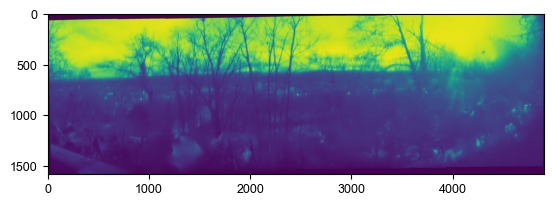

In [5]:
plt.imshow(target_img0)

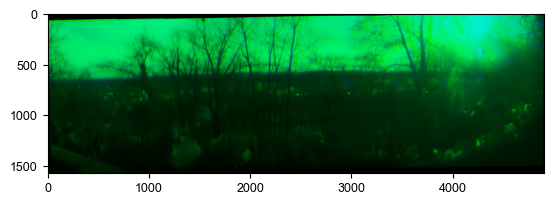

In [6]:
g1 = target_img1[:, :4900]
g0 = target_img0[:1574, :4900]

g1 = g1.astype(np.uint8)
g0 = g0.astype(np.uint8)

zeros = np.zeros_like(g0, dtype=np.uint8)

rgb = np.stack([zeros, g0, g1], axis=-1)
bgr = np.stack([g1, g0, zeros], axis=-1)
plt.imshow(rgb)

In [7]:
mix1param=np.load('/gpfs01/euler/User/ydeng/Github/camNscan_dataAnalysis/notebooks/SCAM_data/param_dict_mix_seed1_07072025.pkl',
            allow_pickle=True)
trajectory = mix1param['trajectory']

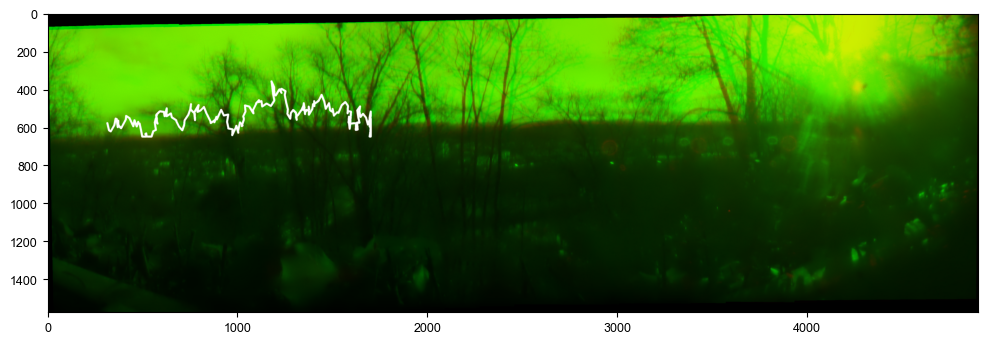

In [8]:
crop_pano=np.copy(bgr)
image = np.copy(crop_pano)
x_positions = [pos[0] for pos in trajectory]
y_positions = [pos[1] for pos in trajectory]
# for i in range(1, len(x_positions)):
for i in range(1, 240):
    pt1 = (x_positions[i - 1], y_positions[i - 1])
    pt2 = (x_positions[i], y_positions[i])
    cv2.line(image, pt1, pt2, color=(255,255,255), thickness=10)
plt.figure(figsize=(12, 8))
plt.imshow(image)

In [9]:
x_positions =[pos[0] for pos in trajectory]
y_positions = [pos[1] for pos in trajectory]
# Parameters for cropping
crop_size=600
crops_uv = []
crops_g = []
for x, y in zip(x_positions, y_positions):
    x1 = max(0, x - crop_size // 2)
    x2 = min(target_img0.shape[1], x + crop_size // 2)
    y1 = max(0, y - crop_size // 2)
    y2 = min(target_img0.shape[0], y + crop_size // 2)
    crop_uv = target_img1[y1:y2, x1:x2]
    crop_g = target_img0[y1:y2, x1:x2]
    crops_uv.append(crop_uv)
    crops_g.append(crop_g)

In [52]:
np.sum(crop_g-crop_uv)/crop_g.shape[0]/crop_g.shape[1]

57.911925

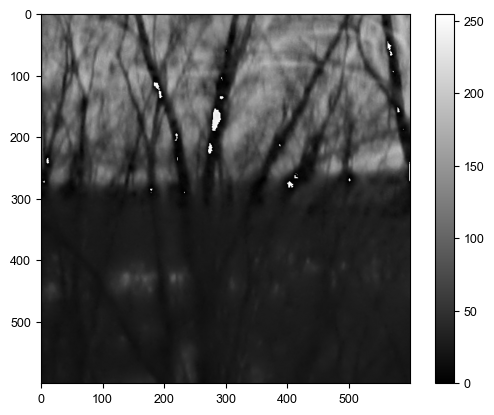

In [49]:
im = plt.imshow(crop_g-crop_uv,vmin=0,vmax=255,cmap='gray')
plt.colorbar(im)

In [10]:
crops_g = np.asarray(crops_g)
crops_g.shape

(600, 600, 600)

In [11]:
crops_uv = np.asarray(crops_uv)
crops_uv.shape

(600, 600, 600)

In [43]:
np.savez('./SCAM_20251208_140023/movie_config_09122025.npz',
         crops_uv=crops_uv,
         crops_g = crops_g,
         pano_cam1 = target_img1,
         pano_cam0 = target_img0,
         trajectory = mix1param['trajectory'])

## G-G, UVG, UVUV

In [12]:
height, width = 300, 300
fps = 60

numFrame,crop_size,crop_size = crops_uv.shape
f_name = './GG.avi'

GG = np.zeros((8*30,crop_size,crop_size,3))
GG[:240,:,:,0]= crops_g[:240] # Blue-channel
GG[:240,:,:,1]= crops_g[:240] # Green-channel
print(GG.shape)

UVG = np.zeros((8*30,crop_size,crop_size,3))
UVG[:240,:,:,0]= crops_uv[:240] # Blue-channel
UVG[:240,:,:,1]= crops_g[:240] # Green-channel
print(UVG.shape)

UVUV = np.zeros((8*30,crop_size,crop_size,3))
UVUV[:240,:,:,0]= crops_uv[:240] # Blue-channel
UVUV[:240,:,:,1]= crops_uv[:240] # Green-channel
print(UVUV.shape)

(240, 600, 600, 3)
(240, 600, 600, 3)
(240, 600, 600, 3)


In [57]:
np.mean(UVG[:,:,:,0])

45.60212042824074

In [32]:
UV_ = np.zeros((8*30,crop_size,crop_size,3))
UV_[:240,:,:,0]= crops_uv[:240] # Blue-channel

print(UV_.shape)

_G = np.zeros((8*30,crop_size,crop_size,3))
_G[:240,:,:,1]= crops_g[:240] # Green-channel

print(UV_.shape)

(240, 600, 600, 3)
(240, 600, 600, 3)


In [35]:
orders2avi = {
    0:GG,
    1:UVUV,
    2:UVG,
    3:UV_,
    4:_G
}

In [40]:
np.random.seed(42)
import numpy as np
orders= np.array([0]*6 + [1]*6 + [2]*6)
np.random.shuffle(orders)

In [41]:
orders

array([0, 0, 1, 0, 0, 2, 2, 2, 1, 0, 1, 2, 0, 2, 1, 1, 2, 1])

In [36]:
np.random.seed(42)
import numpy as np
orders_5snip= np.array([0]*6 + [1]*6 + [2]*6+[3]*6+[4]*6)
np.random.shuffle(orders_5snip)
print(orders_5snip)

[4 2 3 2 1 1 4 4 2 0 0 2 0 2 1 3 0 0 4 0 3 4 3 4 3 1 1 2 3 1]


In [17]:
## double-ch avi
avis_list = [orders2avi[oo] for oo in orders]
repeated_toAVI = np.concatenate(avis_list)
arr = repeated_toAVI.astype(np.uint8) 
print(f'numF {arr.shape}')
# Resize and rotate
resized_frames = []
for i in range(len(arr)):
    resized = cv2.resize(arr[i], (height, width), interpolation=cv2.INTER_CUBIC)
    rotated = cv2.rotate(resized, cv2.ROTATE_90_CLOCKWISE)  # shape (300, 300, 3)
    resized_frames.append(rotated)
# duplicate frames for 60Hz
resized_frames = np.repeat(resized_frames, repeats=2, axis=0)
print(len(resized_frames))
f_name='./GGUVUVUVG_6reps.avi'
fourcc = cv2.VideoWriter_fourcc(*'MJPG')
out = cv2.VideoWriter(f_name, fourcc, fps, (width, height))
for ff,frame in enumerate(resized_frames):
    if ff%60 ==0:
        print(f'{ff/60}second')
    out.write(frame)

out.release()
del resized_frames
del repeated_toAVI

In [39]:
## double-ch * single_ch avi
avis_list = [orders2avi[oo] for oo in orders_5snip]
repeated_toAVI = np.concatenate(avis_list)
arr = repeated_toAVI.astype(np.uint8) 
print(f'numF {arr.shape}')
# Resize and rotate
resized_frames = []
for i in range(len(arr)):
    resized = cv2.resize(arr[i], (height, width), interpolation=cv2.INTER_CUBIC)
    rotated = cv2.rotate(resized, cv2.ROTATE_90_CLOCKWISE)  # shape (300, 300, 3)
    resized_frames.append(rotated)
# duplicate frames for 60Hz
resized_frames = np.repeat(resized_frames, repeats=2, axis=0)
print(len(resized_frames))
f_name='./5combos_6reps.avi'
fourcc = cv2.VideoWriter_fourcc(*'MJPG')
out = cv2.VideoWriter(f_name, fourcc, fps, (width, height))
for ff,frame in enumerate(resized_frames):
    if ff%60 ==0:
        print(f'{ff/60}second')
    out.write(frame)

out.release()
del resized_frames
del repeated_toAVI

numF (7200, 600, 600, 3)
14400
0.0second
1.0second
2.0second
3.0second
4.0second
5.0second
6.0second
7.0second
8.0second
9.0second
10.0second
11.0second
12.0second
13.0second
14.0second
15.0second
16.0second
17.0second
18.0second
19.0second
20.0second
21.0second
22.0second
23.0second
24.0second
25.0second
26.0second
27.0second
28.0second
29.0second
30.0second
31.0second
32.0second
33.0second
34.0second
35.0second
36.0second
37.0second
38.0second
39.0second
40.0second
41.0second
42.0second
43.0second
44.0second
45.0second
46.0second
47.0second
48.0second
49.0second
50.0second
51.0second
52.0second
53.0second
54.0second
55.0second
56.0second
57.0second
58.0second
59.0second
60.0second
61.0second
62.0second
63.0second
64.0second
65.0second
66.0second
67.0second
68.0second
69.0second
70.0second
71.0second
72.0second
73.0second
74.0second
75.0second
76.0second
77.0second
78.0second
79.0second
80.0second
81.0second
82.0second
83.0second
84.0second
85.0second
86.0second
87.0second
88.0second


## UVG 6 repeats

In [25]:
repeated_toAVI = np.concatenate([UVG,UVG,UVG,UVG,UVG,UVG])
arr = repeated_toAVI.astype(np.uint8)  # Ensure data type is uint8
print(f'numF {arr.shape}')
# Resize and rotate
resized_frames = []
for i in range(len(arr)):
    resized = cv2.resize(arr[i], (height, width), interpolation=cv2.INTER_CUBIC)
    rotated = cv2.rotate(resized, cv2.ROTATE_90_CLOCKWISE)  # shape (300, 300, 3)
    resized_frames.append(rotated)
# duplicate frames for 60Hz
resized_frames = np.repeat(resized_frames, repeats=2, axis=0)
print(len(resized_frames))
f_name='./UVG_6reps.avi'
fourcc = cv2.VideoWriter_fourcc(*'MJPG')
out = cv2.VideoWriter(f_name, fourcc, fps, (width, height))
for ff,frame in enumerate(resized_frames):
    if ff%60 ==0:
        print(f'{ff/60}second')
    out.write(frame)

out.release()

numF (1440, 600, 600, 3)
2880
0.0second
1.0second
2.0second
3.0second
4.0second
5.0second
6.0second
7.0second
8.0second
9.0second
10.0second
11.0second
12.0second
13.0second
14.0second
15.0second
16.0second
17.0second
18.0second
19.0second
20.0second
21.0second
22.0second
23.0second
24.0second
25.0second
26.0second
27.0second
28.0second
29.0second
30.0second
31.0second
32.0second
33.0second
34.0second
35.0second
36.0second
37.0second
38.0second
39.0second
40.0second
41.0second
42.0second
43.0second
44.0second
45.0second
46.0second
47.0second
